In [26]:
from plotting_helpers import get_job_table_df, get_power_trace_df
from peacsim.parsing import job_profile_reader as job_parser
import numpy as np
import matplotlib.pyplot as plt
# import seaborn as sns
import pandas as pd

In [27]:
optimization_dir = "opt_flex-resource_probabilities=0.8,0.8,0.8,0.8_SA_inf_low_util_RSR_1000server_exp_inf_low_util=0.6_W2-short-qos5_4.5_4_3.5_dynamic_signal_20250915100931/"

weigts_file_path = "../output/optimization/" + optimization_dir + "/opt_weights.csv"   ### mock_weights.csv

exp_name = "flex_resource_prob=0.8_dr_RSR_exp_inf_low_util=0.6_W2-short-qos5_4.5_4_3.5_dynamic_signal_qos0.9_20250917111611" # "DEBUG_AVAIL_W2-simulated_annealing_low_util_RSR_50server_20250309205545" # "W2_NoDR_50server_20250308132744" # "availability_50server_20250306143558" # "W2-simulated_annealing_low_util_50server_test_20250306115615"

output_dir = "../output/simulation/" + exp_name

job_table = get_job_table_df(output_dir)
power_df = get_power_trace_df(output_dir)


In [28]:
 # Replace with the actual file path
weights_df = pd.read_csv(weigts_file_path)

# Convert to dictionary
job_type_weights = weights_df.set_index('job_type_id')['weights'].to_dict()


state_columns = [col for col in power_df.columns if col.startswith('state')]

# Step 2: Calculate job type distributions over time
# Melt the DataFrame to make it long-format for easier processing
melted = power_df.melt(id_vars='time', value_vars=state_columns, var_name='server', value_name='job_type')

# Exclude inactive servers
active_jobs = melted[melted['job_type'] != -1]

# Count job types per time
active_job_type_counts = active_jobs.groupby(['time', 'job_type']).size().unstack(fill_value=0)

# Step 3: Normalize counts to get ratios
active_job_type_ratios = active_job_type_counts.div(active_job_type_counts.sum(axis=1), axis=0)


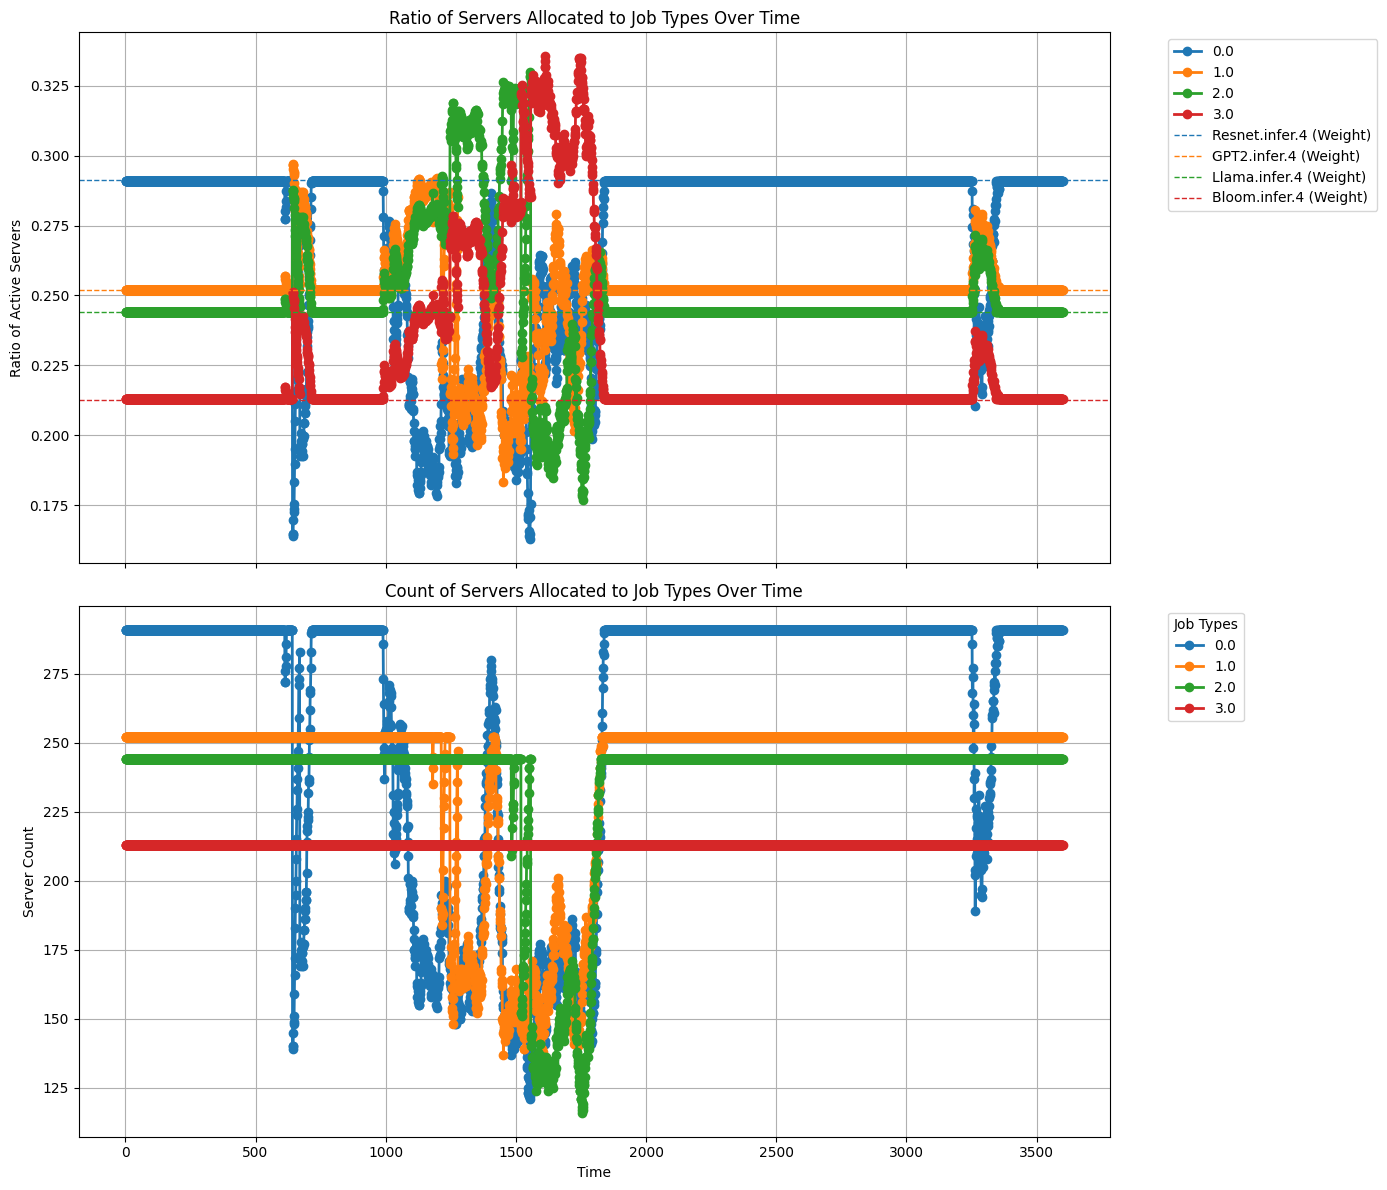

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

# Plot 1: Ratios with weights
active_job_type_ratios.plot(kind='line', marker='o', linewidth=2, ax=axes[0], legend=False)
for i, (job_type, weight) in enumerate(job_type_weights.items()):
    color = axes[0].lines[i].get_color()  # Get the color of the line
    axes[0].axhline(y=weight, color=color, linestyle='--', linewidth=1, label=f'{job_type} (Weight)')

axes[0].set_title('Ratio of Servers Allocated to Job Types Over Time')
axes[0].set_ylabel('Ratio of Active Servers')
axes[0].legend(title='', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].grid(True)

# Plot 2: Counts
active_job_type_counts.plot(kind='line', marker='o', linewidth=2, ax=axes[1], legend=True)
axes[1].set_title('Count of Servers Allocated to Job Types Over Time')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Server Count')
axes[1].legend(title='Job Types', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].grid(True)

plt.tight_layout()
plt.savefig(exp_name + "job_type_server_allocs_combined.pdf", format='pdf')
plt.show()


In [30]:
waiting_jobs = pd.read_csv(output_dir + "/waiting_jobs_by_job_type.csv")
waiting_jobs.fillna(0, inplace=True)
waiting_jobs.index += 1
active_job_type_counts.columns = waiting_jobs.columns

In [20]:
waiting_jobs

,0,1,2,3
1,287,247,250,223.0
2,9,5,25,16.0
3,4,7,28,19.0
4,9,8,35,23.0
5,17,8,36,35.0
...,...,...,...,...
3597,125,250,1018,1490.0
3598,125,249,1023,1492.0
3599,129,247,1023,1497.0
3600,127,242,1029,1499.0


In [21]:
weights_df['weights'].values

array([0.29597685, 0.26564838, 0.22984913, 0.20852564])

In [22]:
num_servers = 1000
weights = np.asarray(weights_df['weights'].values)
guaranteed_resources = (num_servers * weights)  ### TODO ROUND OR NOT
guaranteed_resources.reshape(1, len(guaranteed_resources))

array([[295.97684892, 265.64838294, 229.84913233, 208.52563581]])

In [23]:
waiting_and_active_jobs_sum = active_job_type_counts.add(waiting_jobs, fill_value=0)


In [31]:
# Convert guaranteed_resources to a DataFrame
guaranteed_resources_df = pd.DataFrame([guaranteed_resources], columns=waiting_and_active_jobs_sum.columns)

# Compare guaranteed resources with each row of the summed DataFrame
comparison_result = waiting_and_active_jobs_sum.ge(guaranteed_resources_df.iloc[0], axis=1)

# Display the result
comparison_result

,0,1,2,3
1,True,True,True,True
2,True,False,True,True
3,True,True,True,True
4,True,True,True,True
5,True,True,True,True
...,...,...,...,...
3597,True,True,True,True
3598,True,True,True,True
3599,True,True,True,True
3600,True,True,True,True


In [32]:
# Count the number of True values in each column
true_counts = comparison_result.sum()

# Calculate the percentage of True values in each column
true_ratio = (true_counts / len(comparison_result))

# Display the result
true_ratio

0    0.543738
1    0.661761
2    0.926409
3    0.984726
dtype: float64

In [33]:
probabilities = np.asarray([0.7, 0.75, 0.8, 0.85])

cost = np.maximum(0,probabilities - true_ratio.values)

In [34]:
cost

array([0.15626215, 0.08823938, 0.        , 0.        ])

In [35]:
true_ratio

0    0.543738
1    0.661761
2    0.926409
3    0.984726
dtype: float64

In [15]:
cost_per_job_type = np.asarray([0.2, 0,-0.1, -0.3, -0.2])

In [16]:
cost_per_job_type_negated = cost_per_job_type * -1
print(cost_per_job_type_negated)

[-0.2 -0.   0.1  0.3  0.2]


In [17]:
cost_per_job_type_negated
min_val = np.min(cost_per_job_type_negated)
max_val = np.max(cost_per_job_type_negated)
normalized_cost_per_job_type = (cost_per_job_type_negated - min_val) / (max_val - min_val)

In [18]:
cost_per_job_type = np.asarray([0.2, 0, -0.1, -0.3, -0.2])

# Negate costs
cost_per_job_type_negated = -cost_per_job_type

# Compute a normalized weight adjustment factor (keeping zero-centered adjustments)
min_val = np.min(cost_per_job_type_negated)
max_val = np.max(cost_per_job_type_negated)
range_val = max_val - min_val

if range_val > 0:
    normalized_cost_per_job_type = (cost_per_job_type_negated - min_val) / range_val
else:
    normalized_cost_per_job_type = np.zeros_like(cost_per_job_type_negated)  # Avoid division by zero

# Initialize weights
w = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
step_size = 0.01

# Multiplicative update
w *= (1 + step_size * (2 * normalized_cost_per_job_type - 1))  # Shift range to [-1,1]

# Ensure weights remain non-negative
w = np.maximum(w, 0)
w = w / np.sum(w)
w

array([0.19776268, 0.19936077, 0.20015981, 0.20175789, 0.20095885])

In [19]:
normalized_cost_per_job_type

array([0. , 0.4, 0.6, 1. , 0.8])